# Sentiment Intelligence — Preprocessing and Data Splitting

## Notebook 02: Duplicate-aware Splitting and Preprocessing Analysis

**Objective**
1. Establish stable record and duplicate-group identifiers.
2. Compare conservative text-normalisation alternatives.
3. Preserve sentiment-bearing negation terms.
4. Create reproducible, leakage-safe train/validation/test partitions.
5. Create three leave-one-source-out cross-domain evaluations.
6. Save partition files and manifests for identical reuse across ML and DL models.

**Labels:** 0 = Negative, 1 = Positive.

**Important:** This notebook does not fit a vocabulary, TF-IDF vectoriser, tokenizer,
or any other learned transformation. Those must be fitted on training data only
inside the later model-training workflows.


## 1. Imports and project paths

In [21]:
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
N_SPLITS = 5

cwd = Path.cwd()
PROJECT_ROOT = next(
    (
        p for p in [cwd, *cwd.parents]
        if (
            p / "data/interim/sentiment/"
            "sentiment_labelled_sentences.csv"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root.")

DATA_PATH = (
    PROJECT_ROOT / "data/interim/sentiment/"
    "sentiment_labelled_sentences.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "data/processed/sentiment"
CROSS_DOMAIN_DIR = OUTPUT_DIR / "cross_domain"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROSS_DOMAIN_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Input dataset:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)


Project root: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent
Input dataset: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/interim/sentiment/sentiment_labelled_sentences.csv
Output directory: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment


## 2. Load data and create stable identifiers

In [22]:
df = pd.read_csv(DATA_PATH)

required_columns = {"source", "text", "label"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

if df[list(required_columns)].isna().any().any():
    raise ValueError("Null values found in required columns.")

df["source"] = df["source"].astype(str).str.lower()
df["text"] = df["text"].astype(str)
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Labels must be binary: 0 or 1.")

# Deterministic source-local row number and record identifier.
df["source_row_number"] = (
    df.groupby("source", sort=False).cumcount() + 1
)

df["record_id"] = (
    df["source"]
    + "_"
    + df["source_row_number"].astype(str).str.zfill(4)
)

# Match the normalisation convention used during the previous exploration.
# Punctuation is retained; only case and repeated whitespace are normalised.
df["group_key"] = (
    df["text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["group_id"] = df["group_key"].map(
    lambda value: hashlib.sha256(
        value.encode("utf-8")
    ).hexdigest()[:20]
)

# Composite stratum preserves source and sentiment balance together.
df["stratum"] = (
    df["source"] + "__" + df["label"].astype(str)
)

assert df["record_id"].is_unique
assert df["group_id"].notna().all()
assert df["group_key"].ne("").all()

print("Rows:", len(df))
print("Unique records:", df["record_id"].nunique())
print("Unique normalised sentence groups:", df["group_id"].nunique())

display(df[["record_id", "source", "text", "label", "group_id"]].head())


Rows: 3000
Unique records: 3000
Unique normalised sentence groups: 2979


,record_id,source,text,label,group_id
0,amazon_0001,amazon,So there is no way for me to plug it in here in the US unless I go by a converter.,0,dc46193ac4de315cbb39
1,amazon_0002,amazon,"Good case, Excellent value.",1,70161b68de47f6c1cf02
2,amazon_0003,amazon,Great for the jawbone.,1,bbe8ef479eb7662324cb
3,amazon_0004,amazon,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,0bc7dea4e5e74c3be5f5
4,amazon_0005,amazon,The mic is great.,1,79a22edacb9c51006573


## 3. Duplicate groups and label consistency

Repeated sentences are retained. All rows with the same normalised sentence
are assigned to a single group, ensuring that a group cannot cross partitions.

Conflicting labels within one normalised sentence group are treated as a data
quality issue and must be investigated before model training.


In [23]:
duplicate_groups = (
    df.groupby("group_id")
    .agg(
        occurrences=("record_id", "size"),
        distinct_sources=("source", "nunique"),
        distinct_labels=("label", "nunique"),
        sources=("source", lambda x: ", ".join(sorted(set(x)))),
        labels=("label", lambda x: sorted(set(x))),
        example_text=("text", "first"),
    )
)

repeated_groups = duplicate_groups[
    duplicate_groups["occurrences"] > 1
]

cross_source_groups = duplicate_groups[
    duplicate_groups["distinct_sources"] > 1
]

conflicting_groups = duplicate_groups[
    duplicate_groups["distinct_labels"] > 1
]

display(pd.Series({
    "total_rows": len(df),
    "unique_groups": len(duplicate_groups),
    "repeated_groups": len(repeated_groups),
    "rows_in_repeated_groups": int(
        repeated_groups["occurrences"].sum()
    ),
    "cross_source_groups": len(cross_source_groups),
    "conflicting_label_groups": len(conflicting_groups),
}).to_frame("count"))

display(cross_source_groups)

if len(conflicting_groups):
    display(conflicting_groups)
    raise ValueError(
        "Conflicting labels detected within duplicate groups. "
        "Investigate before splitting."
    )

print("Duplicate-group consistency check passed.")


,count
total_rows,3000
unique_groups,2979
repeated_groups,19
rows_in_repeated_groups,40
cross_source_groups,1
conflicting_label_groups,0


,occurrences,distinct_sources,distinct_labels,sources,labels,example_text
group_id,,,,,,
304b8340137943d8b027,2,2,1,"amazon, imdb",[0],Very disappointing.


Duplicate-group consistency check passed.


## 4. Compare conservative preprocessing alternatives

We retain three views of the same sentence:
- `raw`: original sentence, unchanged.
- `lowercase_whitespace`: lowercased with repeated whitespace normalised.
- `punctuation_removed`: punctuation removed experimentally, with apostrophes
  retained to avoid breaking common contractions.

These are exploratory alternatives, not final decisions. No stopwords are
removed, and negation terms must remain available to every model.


In [24]:
def lowercase_whitespace(text: str) -> str:
    return re.sub(r"\s+", " ", text.lower()).strip()


def punctuation_removed(text: str) -> str:
    lowered = text.lower()
    without_punctuation = re.sub(r"[^\w\s']", " " , lowered)
    return re.sub(r"\s+", " ", without_punctuation).strip()


df["text_lowercase"] = df["text"].map(lowercase_whitespace)
df["text_no_punctuation"] = df["text"].map(punctuation_removed)

preprocessing_examples = df[
    ["source", "label", "text", "text_lowercase", "text_no_punctuation"]
].sample(n=15, random_state=RANDOM_STATE)

display(preprocessing_examples)


,source,label,text,text_lowercase,text_no_punctuation
1801,imdb,0,Avoid at ALL costs!,avoid at all costs!,avoid at all costs
1190,imdb,1,"Garbo, who showed right off the bat that her talents could carry over from the silent era (I wanted to see some of h...","garbo, who showed right off the bat that her talents could carry over from the silent era (i wanted to see some of h...",garbo who showed right off the bat that her talents could carry over from the silent era i wanted to see some of her...
1817,imdb,1,You will leave the theater wanting to go out and dance under the stars.,you will leave the theater wanting to go out and dance under the stars.,you will leave the theater wanting to go out and dance under the stars
251,amazon,1,O my gosh the best phone I have ever had.,o my gosh the best phone i have ever had.,o my gosh the best phone i have ever had
2505,yelp,0,I would not recommend this place.,i would not recommend this place.,i would not recommend this place
1117,imdb,0,Then scene where they debated whether or not to sack the trumpeter (who falsely was accused for the murder) is pure ...,then scene where they debated whether or not to sack the trumpeter (who falsely was accused for the murder) is pure ...,then scene where they debated whether or not to sack the trumpeter who falsely was accused for the murder is pure ho...
1411,imdb,1,Her role was played well.,her role was played well.,her role was played well
2113,yelp,1,"Nice, spicy and tender.","nice, spicy and tender.",nice spicy and tender
408,amazon,1,Plantronics Bluetooth Excelent Buy.,plantronics bluetooth excelent buy.,plantronics bluetooth excelent buy
2579,yelp,1,"As for the service: I'm a fan, because it's quick and you're being served by some nice folks.","as for the service: i'm a fan, because it's quick and you're being served by some nice folks.",as for the service i'm a fan because it's quick and you're being served by some nice folks


,raw_whitespace,lowercase_whitespace,punctuation_removed,regex_tokens
count,3000.00,3000.00,3000.00,3000.00
mean,11.83,11.83,11.89,11.89
std,7.87,7.87,7.96,7.96
min,1.00,1.00,1.00,1.00
50%,10.00,10.00,10.00,10.00
75%,16.00,16.00,16.00,16.00
90%,22.00,22.00,22.00,22.00
95%,26.00,26.00,26.00,26.00
99%,36.00,36.00,36.00,36.00
max,71.00,71.00,73.00,73.00


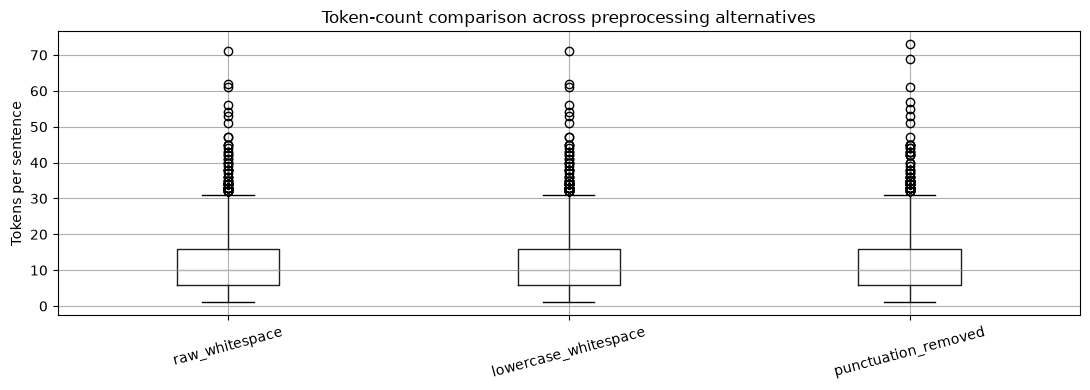

In [25]:
def whitespace_token_count(text: str) -> int:
    return len(text.split())


def regex_token_count(text: str) -> int:
    return len(re.findall(r"[\w]+(?:'[\w]+)?", text.lower()))


length_comparison = pd.DataFrame({
    "raw_whitespace": df["text"].map(whitespace_token_count),
    "lowercase_whitespace": df["text_lowercase"].map(whitespace_token_count),
    "punctuation_removed": df["text_no_punctuation"].map(
        whitespace_token_count
    ),
    "regex_tokens": df["text"].map(regex_token_count),
})

display(
    length_comparison.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

fig, ax = plt.subplots(figsize=(11, 4))
length_comparison[
    ["raw_whitespace", "lowercase_whitespace", "punctuation_removed"]
].boxplot(ax=ax)
ax.set_title("Token-count comparison across preprocessing alternatives")
ax.set_ylabel("Tokens per sentence")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


## 5. Negation preservation

Removing stopwords can remove important sentiment information. Negations such
as `not`, `never`, `no`, `without`, and contractions such as `don't` and
`isn't` may reverse the meaning of a sentence.

We inspect their occurrence without removing or transforming them.


In [26]:
NEGATION_TERMS = {
    "no", "not", "never", "without", "hardly", "cannot",
    "can't", "don't", "doesn't", "didn't", "isn't", "aren't",
    "wasn't", "weren't", "won't", "wouldn't", "shouldn't",
    "couldn't", "mustn't",
}


def sentence_tokens(text: str) -> list[str]:
    return re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", text.lower())


def find_negations(text: str) -> set[str]:
    return set(sentence_tokens(text)).intersection(NEGATION_TERMS)


df["negation_terms"] = df["text"].map(find_negations)
df["contains_negation"] = df["negation_terms"].map(bool)

negation_summary = (
    df.groupby(["source", "label"])
    .agg(
        records=("record_id", "size"),
        sentences_with_negation=("contains_negation", "sum"),
    )
)

negation_summary["percentage"] = (
    100 * negation_summary["sentences_with_negation"]
    / negation_summary["records"]
)

display(negation_summary.round(2))

print("Examples containing negation:")
display(
    df.loc[
        df["contains_negation"],
        ["source", "label", "text", "negation_terms"],
    ].head(20)
)


records  sentences_with_negation  percentage
source label                                              
amazon 0          500                      164        32.8
       1          500                       49         9.8
imdb   0          500                      145        29.0
       1          500                       61        12.2
yelp   0          500                      201        40.2
       1          500                       42         8.4

Examples containing negation:


,source,label,text,negation_terms
0,amazon,0,So there is no way for me to plug it in here in the US unless I go by a converter.,{no}
14,amazon,0,"The design is very odd, as the ear ""clip"" is not very comfortable at all.",{not}
16,amazon,0,I advise EVERYONE DO NOT BE FOOLED!,{not}
20,amazon,0,"I went on Motorola's website and followed all directions, but could not get it to pair again.",{not}
23,amazon,1,I have yet to run this new battery below two bars and that's three days without charging.,{without}
27,amazon,0,I didn't think that the instructions provided were helpful to me.,{didn't}
29,amazon,0,Doesn't hold charge.,{doesn't}
34,amazon,1,Car charger as well as AC charger are included to make sure you never run out of juice.Highy recommended,{never}
41,amazon,0,I was not impressed by this product.,{not}
50,amazon,0,Not loud enough and doesn't turn on like it should.,"{doesn't, not}"


## 6. Reusable duplicate-aware stratified group split

`StratifiedGroupKFold` attempts to preserve class proportions while keeping
all rows from a group together.

We use the composite `source + label` stratum for the main experiment.
Five folds provide an approximately 80/20 split.

The first split creates train-validation data and test data. A second split
creates training and validation data from the remaining 80%, yielding
approximately 64/16/20 overall.


In [27]:
def group_stratified_holdout(
    frame: pd.DataFrame,
    random_state: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    if len(frame) < N_SPLITS:
        raise ValueError("Not enough rows for the requested group split.")

    splitter = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=random_state,
    )

    train_indices, holdout_indices = next(
        splitter.split(
            X=np.zeros(len(frame)),
            y=frame["stratum"].to_numpy(),
            groups=frame["group_id"].to_numpy(),
        )
    )

    return (
        frame.iloc[train_indices].copy().reset_index(drop=True),
        frame.iloc[holdout_indices].copy().reset_index(drop=True),
    )


def assert_no_group_leakage(
    partitions: dict[str, pd.DataFrame],
) -> None:
    names = list(partitions)

    for i, first_name in enumerate(names):
        first_groups = set(partitions[first_name]["group_id"])

        for second_name in names[i + 1:]:
            second_groups = set(partitions[second_name]["group_id"])
            overlap = first_groups.intersection(second_groups)

            assert not overlap, (
                f"Group leakage between {first_name} and {second_name}: "
                f"{len(overlap)} overlapping groups."
            )


def assert_record_integrity(
    partitions: dict[str, pd.DataFrame],
) -> None:
    record_sets = [
        set(partition["record_id"])
        for partition in partitions.values()
    ]

    for i, first_set in enumerate(record_sets):
        for second_set in record_sets[i + 1:]:
            assert not first_set.intersection(second_set)


def split_summary(partitions: dict[str, pd.DataFrame]) -> pd.DataFrame:
    rows = []

    for name, partition in partitions.items():
        rows.append({
            "partition": name,
            "records": len(partition),
            "percentage": round(
                100 * len(partition) / sum(
                    len(x) for x in partitions.values()
                ),
                2,
            ),
            "unique_groups": partition["group_id"].nunique(),
            "negative": int((partition["label"] == 0).sum()),
            "positive": int((partition["label"] == 1).sum()),
        })

    return pd.DataFrame(rows).set_index("partition")


def display_source_label_distribution(
    partitions: dict[str, pd.DataFrame],
) -> None:
    for name, partition in partitions.items():
        print(f"\\n{name.upper()}")
        display(
            pd.crosstab(
                partition["source"],
                partition["label"],
            ).rename(columns={0: "negative", 1: "positive"})
        )


## 7. Create the main train/validation/test partitions

In [28]:
train_validation, test = group_stratified_holdout(
    df,
    random_state=RANDOM_STATE,
)

train, validation = group_stratified_holdout(
    train_validation,
    random_state=RANDOM_STATE + 1,
)

main_partitions = {
    "train": train,
    "validation": validation,
    "test": test,
}

assert_no_group_leakage(main_partitions)
assert_record_integrity(main_partitions)

# All six source-label strata should be represented in each main partition.
expected_strata = set(df["stratum"].unique())

for name, partition in main_partitions.items():
    assert set(partition["stratum"].unique()) == expected_strata, (
        f"Some source-label strata are missing from {name}."
    )

display(split_summary(main_partitions))
display_source_label_distribution(main_partitions)

print("Main split group-leakage checks passed.")


,records,percentage,unique_groups,negative,positive
partition,,,,,
train,1920,64.0,1908,960,960
validation,480,16.0,477,240,240
test,600,20.0,594,300,300


\nTRAIN


label,negative,positive
source,,
amazon,320,320
imdb,320,320
yelp,320,320


\nVALIDATION


label,negative,positive
source,,
amazon,80,80
imdb,80,80
yelp,80,80


\nTEST


label,negative,positive
source,,
amazon,100,100
imdb,100,100
yelp,100,100


Main split group-leakage checks passed.


## 8. Inspect sequence lengths using training data only

The vocabulary and sequence lengths must not be chosen using the test set.
For this preliminary decision, we inspect token counts in the main training
partition only.

The 95th and 99th percentiles provide useful candidate sequence lengths.
The final sequence length will be selected and validated during LSTM/BiLSTM
experiments.


In [29]:
train_token_lengths = train["text"].map(regex_token_count)

sequence_length_summary = train_token_lengths.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("training_token_count")

display(sequence_length_summary.round(2))

candidate_lengths = {
    "p95_rounded_up": int(np.ceil(train_token_lengths.quantile(0.95))),
    "p99_rounded_up": int(np.ceil(train_token_lengths.quantile(0.99))),
    "training_max": int(train_token_lengths.max()),
}

print("Candidate sequence lengths (training partition only):")
display(pd.Series(candidate_lengths, name="tokens").to_frame())


,training_token_count
count,1920.00
mean,11.84
std,8.07
min,1.00
50%,10.00
75%,16.00
90%,22.00
95%,26.00
99%,36.00
max,73.00


Candidate sequence lengths (training partition only):


,tokens
p95_rounded_up,26
p99_rounded_up,36
training_max,73


## 9. Save the main split files and manifest

Each model will consume these same files. The manifest records the original
input hash, random seed, split sizes, group-leakage status, and label/source
distributions.


In [30]:
INPUT_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

SAVE_COLUMNS = [
    "record_id",
    "source",
    "text",
    "label",
    "group_id",
]


def serialise_partition_counts(
    partitions: dict[str, pd.DataFrame],
) -> dict:
    result = {}

    for name, partition in partitions.items():
        source_counts = {}

        for source in sorted(partition["source"].unique()):
            subset = partition[partition["source"] == source]
            source_counts[source] = {
                "negative": int((subset["label"] == 0).sum()),
                "positive": int((subset["label"] == 1).sum()),
            }

        result[name] = {
            "records": len(partition),
            "unique_groups": int(partition["group_id"].nunique()),
            "source_label_counts": source_counts,
        }

    return result


for name, partition in main_partitions.items():
    partition[SAVE_COLUMNS].to_csv(
        OUTPUT_DIR / f"{name}.csv",
        index=False,
    )

main_manifest = {
    "experiment": "main_duplicate_aware_stratified_group_split",
    "input_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "input_sha256": INPUT_SHA256,
    "random_state": RANDOM_STATE,
    "splitter": "StratifiedGroupKFold",
    "n_splits": N_SPLITS,
    "stratification_target": "source + sentiment label",
    "grouping": "lowercase sentence with whitespace normalisation",
    "requested_approximate_ratios": {
        "train": 0.64,
        "validation": 0.16,
        "test": 0.20,
    },
    "counts": serialise_partition_counts(main_partitions),
    "group_leakage_detected": False,
    "records_preserved": True,
    "candidate_sequence_lengths_from_training_only": candidate_lengths,
}

(OUTPUT_DIR / "main_split_manifest.json").write_text(
    json.dumps(main_manifest, indent=2),
    encoding="utf-8",
)

print("Main split files saved:")
for name in main_partitions:
    print(OUTPUT_DIR / f"{name}.csv")
print(OUTPUT_DIR / "main_split_manifest.json")


Main split files saved:
/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/train.csv
/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/validation.csv
/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/test.csv
/home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/main_split_manifest.json


## 10. Create cross-domain evaluation partitions

For each experiment:
- One source is held out completely for testing.
- The other two sources provide training and validation data.
- Any training-domain record whose normalised sentence group occurs in the
  held-out test source is excluded from the training-domain candidate pool.
- The remaining candidate data is split into approximately 80% training and
  20% validation using duplicate-aware stratified group splitting.

The held-out source remains untouched as the cross-domain test set.


In [31]:
cross_domain_partitions = {}
cross_domain_manifest = {
    "experiment": "leave_one_source_out",
    "input_sha256": INPUT_SHA256,
    "splitter": "StratifiedGroupKFold",
    "n_splits": N_SPLITS,
    "random_state_base": RANDOM_STATE + 100,
    "overlap_policy": (
        "Remove non-test rows whose normalised sentence group appears "
        "in the held-out test source."
    ),
    "experiments": {},
}

for offset, heldout_source in enumerate(sorted(df["source"].unique())):
    test_domain = df[
        df["source"] == heldout_source
    ].copy().reset_index(drop=True)

    candidate_training_domains = df[
        df["source"] != heldout_source
    ].copy()

    test_group_ids = set(test_domain["group_id"])

    overlap_mask = candidate_training_domains["group_id"].isin(
        test_group_ids
    )

    excluded_rows = int(overlap_mask.sum())
    excluded_groups = int(
        candidate_training_domains.loc[
            overlap_mask, "group_id"
        ].nunique()
    )

    candidate_training_domains = (
        candidate_training_domains.loc[~overlap_mask]
        .copy()
        .reset_index(drop=True)
    )

    cross_train, cross_validation = group_stratified_holdout(
        candidate_training_domains,
        random_state=RANDOM_STATE + 100 + offset,
    )

    partitions = {
        "train": cross_train,
        "validation": cross_validation,
        "test": test_domain,
    }

    assert_no_group_leakage(partitions)
    assert_record_integrity(partitions)

    assert set(test_domain["source"].unique()) == {heldout_source}
    assert set(test_domain["label"].unique()) == {0, 1}

    # Both non-held-out sources must remain represented in training and validation.
    expected_training_sources = set(df["source"].unique()) - {heldout_source}

    assert set(cross_train["source"].unique()) == expected_training_sources
    assert set(cross_validation["source"].unique()) == expected_training_sources

    experiment_name = f"heldout_{heldout_source}"

    cross_domain_partitions[experiment_name] = partitions

    experiment_dir = CROSS_DOMAIN_DIR / experiment_name
    experiment_dir.mkdir(parents=True, exist_ok=True)

    for partition_name, partition in partitions.items():
        partition[SAVE_COLUMNS].to_csv(
            experiment_dir / f"{partition_name}.csv",
            index=False,
        )

    cross_domain_manifest["experiments"][experiment_name] = {
        "heldout_source": heldout_source,
        "training_sources": sorted(expected_training_sources),
        "excluded_overlapping_training_rows": excluded_rows,
        "excluded_overlapping_training_groups": excluded_groups,
        "counts": serialise_partition_counts(partitions),
        "group_leakage_detected": False,
    }

    print(f"\\n{experiment_name.upper()}")
    print("Held-out test records:", len(test_domain))
    print("Excluded overlapping training rows:", excluded_rows)
    display(split_summary(partitions))

cross_manifest_path = CROSS_DOMAIN_DIR / "cross_domain_split_manifest.json"
cross_manifest_path.write_text(
    json.dumps(cross_domain_manifest, indent=2),
    encoding="utf-8",
)

print("\\nCross-domain split files saved under:", CROSS_DOMAIN_DIR)
print("Manifest:", cross_manifest_path)


\nHELDOUT_AMAZON
Held-out test records: 1000
Excluded overlapping training rows: 1


,records,percentage,unique_groups,negative,positive
partition,,,,,
train,1599,53.32,1594,799,800
validation,400,13.34,398,200,200
test,1000,33.34,987,500,500


\nHELDOUT_IMDB
Held-out test records: 1000
Excluded overlapping training rows: 1


,records,percentage,unique_groups,negative,positive
partition,,,,,
train,1599,53.32,1586,799,800
validation,400,13.34,396,200,200
test,1000,33.34,997,500,500


\nHELDOUT_YELP
Held-out test records: 1000
Excluded overlapping training rows: 0


,records,percentage,unique_groups,negative,positive
partition,,,,,
train,1600,53.33,1588,800,800
validation,400,13.33,395,200,200
test,1000,33.33,996,500,500


\nCross-domain split files saved under: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/cross_domain
Manifest: /home/anupam9k/ai_projects/03_Async_Market_Intelligence_&_Research_Agent/data/processed/sentiment/cross_domain/cross_domain_split_manifest.json


## 11. Final saved-file verification

In [32]:
expected_main_files = [
    OUTPUT_DIR / "train.csv",
    OUTPUT_DIR / "validation.csv",
    OUTPUT_DIR / "test.csv",
    OUTPUT_DIR / "main_split_manifest.json",
]

expected_cross_files = []

for experiment_name in cross_domain_partitions:
    experiment_dir = CROSS_DOMAIN_DIR / experiment_name
    expected_cross_files.extend([
        experiment_dir / "train.csv",
        experiment_dir / "validation.csv",
        experiment_dir / "test.csv",
    ])

expected_cross_files.append(
    CROSS_DOMAIN_DIR / "cross_domain_split_manifest.json"
)

all_expected_files = expected_main_files + expected_cross_files

missing_files = [p for p in all_expected_files if not p.exists()]

if missing_files:
    raise FileNotFoundError(f"Missing split files: {missing_files}")

print("Verified files:")
for file_path in all_expected_files:
    print(
        f"{file_path.relative_to(PROJECT_ROOT)} "
        f"({file_path.stat().st_size:,} bytes)"
    )

# Re-read main split CSVs and independently verify group separation.
reloaded_main = {
    name: pd.read_csv(OUTPUT_DIR / f"{name}.csv")
    for name in ["train", "validation", "test"]
}

assert_no_group_leakage(reloaded_main)
assert_record_integrity(reloaded_main)

print("\\nALL SPLIT VALIDATION CHECKS PASSED")


Verified files:
data/processed/sentiment/train.csv (202,384 bytes)
data/processed/sentiment/validation.csv (51,814 bytes)
data/processed/sentiment/test.csv (62,769 bytes)
data/processed/sentiment/main_split_manifest.json (1,813 bytes)
data/processed/sentiment/cross_domain/heldout_amazon/train.csv (174,881 bytes)
data/processed/sentiment/cross_domain/heldout_amazon/validation.csv (43,282 bytes)
data/processed/sentiment/cross_domain/heldout_amazon/test.csv (98,746 bytes)
data/processed/sentiment/cross_domain/heldout_imdb/train.csv (156,126 bytes)
data/processed/sentiment/cross_domain/heldout_imdb/validation.csv (40,534 bytes)
data/processed/sentiment/cross_domain/heldout_imdb/test.csv (120,245 bytes)
data/processed/sentiment/cross_domain/heldout_yelp/train.csv (174,204 bytes)
data/processed/sentiment/cross_domain/heldout_yelp/validation.csv (44,787 bytes)
data/processed/sentiment/cross_domain/heldout_yelp/test.csv (97,976 bytes)
data/processed/sentiment/cross_domain/cross_domain_split_ma

## 12. Experiment decisions and next steps

### Frozen decisions
- Original sentences are preserved.
- Duplicate records are not globally deleted.
- Identical normalised sentences cannot cross partitions.
- Main evaluation uses source-and-label stratification.
- Cross-domain tests hold out Amazon, IMDb, and Yelp in separate experiments.
- TF-IDF and neural vocabulary/tokenizer fitting must use training data only.
- Negation terms are not removed by default.

### Still to be decided empirically
- Whether punctuation removal helps or hurts.
- Whether lowercasing helps each model family.
- Whether stopword handling changes performance (negation must be preserved).
- TF-IDF word/character n-gram configurations.
- LSTM/BiLSTM vocabulary size, embedding dimension, sequence length, dropout,
  hidden dimensions, batch size and early-stopping configuration.

### Next notebook
`03_classical_ml_model_comparison.ipynb`

We will compare TF-IDF + Logistic Regression, Multinomial Naive Bayes,
and Linear SVM with a shared set of saved partitions and controlled metrics.
